In [ ]:
import torch

print("PyTorch 버전:", torch.__version__)

if torch.cuda.is_available():
    print("GPU 사용 가능!")
    print("GPU 이름:", torch.cuda.get_device_name(0))
else:
    print("GPU 사용 불가능. CPU로 진행합니다.")

PyTorch 버전: 2.14.1+cu130
GPU 사용 가능!
GPU 이름: Tesla T4


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
import zipfile
import os

# 업로드한 ZIP 파일 이름 확인
zip_name = list(uploaded.keys())[0]

# 압축을 풀 폴더 만들기
extract_path = "/content/garbage_dataset"

os.makedirs(extract_path, exist_ok=True)

# 압축 풀기
with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("압축 해제 완료!")
print("저장 위치:", extract_path)

압축 해제 완료!
저장 위치: /content/garbage_dataset


In [ ]:
import os

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        if level == 2:
            continue

garbage_dataset/
  garbage_classification/
    trash/
    battery/
    white-glass/
    metal/
    paper/
    clothes/
    shoes/
    green-glass/
    brown-glass/
    cardboard/
    biological/
    plastic/


In [ ]:
import os

for root, dirs, files in os.walk(extract_path):
    image_files = [
        f for f in files
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    if image_files:
        print(os.path.basename(root), ":", len(image_files), "장")

trash : 697 장
battery : 945 장
white-glass : 775 장
metal : 769 장
paper : 1050 장
clothes : 5325 장
shoes : 1977 장
green-glass : 629 장
brown-glass : 607 장
cardboard : 891 장
biological : 985 장
plastic : 865 장


In [ ]:
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt
import numpy as np

print("이미지 전처리 준비 완료!")

이미지 전처리 준비 완료!


In [ ]:
import os

print("압축 해제 폴더:", extract_path)

for folder in os.listdir(extract_path):
    path = os.path.join(extract_path, folder)

    if os.path.isdir(path):
        print("폴더:", folder)
        print("하위 폴더:", os.listdir(path)[:15])

압축 해제 폴더: /content/garbage_dataset
폴더: garbage_classification
하위 폴더: ['trash', 'battery', 'white-glass', 'metal', 'paper', 'clothes', 'shoes', 'green-glass', 'brown-glass', 'cardboard', 'biological', 'plastic']


In [ ]:
data_dir = "/content/garbage_dataset/garbage_classification"

print("이미지 데이터 위치:", data_dir)

이미지 데이터 위치: /content/garbage_dataset/garbage_classification


In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(
    root=data_dir,
    transform=transform
)

print("전체 이미지 개수:", len(dataset))
print("분류 종류:", dataset.classes)
print("분류 개수:", len(dataset.classes))

전체 이미지 개수: 15515
분류 종류: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
분류 개수: 12


In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

targets = dataset.targets

train_idx, temp_idx = train_test_split(
    np.arange(len(dataset)),
    test_size=0.30,
    random_state=42,
    stratify=targets
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=np.array(targets)[temp_idx]
)

train_data = Subset(dataset, train_idx)
val_data = Subset(dataset, val_idx)
test_data = Subset(dataset, test_idx)

print("학습 데이터:", len(train_data))
print("검증 데이터:", len(val_data))
print("테스트 데이터:", len(test_data))

학습 데이터: 10860
검증 데이터: 2327
테스트 데이터: 2328


In [ ]:
batch_size = 32

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoader 생성 완료!")

DataLoader 생성 완료!


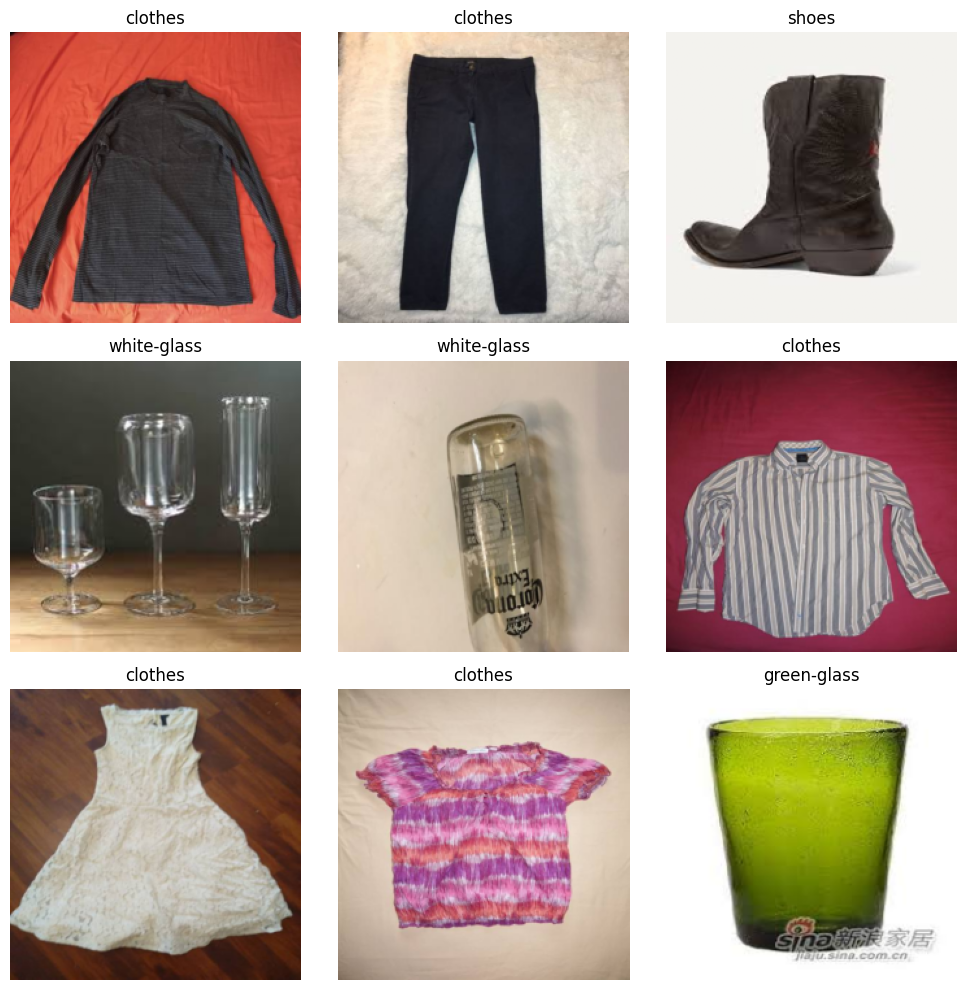

In [ ]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    image = images[i].permute(1, 2, 0)

    plt.imshow(image)
    plt.title(dataset.classes[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn

# GPU 또는 CPU 선택
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("사용 장치:", device)


# CNN 모델 만들기
class GarbageCNN(nn.Module):

    def __init__(self, num_classes):
        super(GarbageCNN, self).__init__()

        # 이미지 특징 추출 부분
        self.features = nn.Sequential(

            # 첫 번째 층
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 두 번째 층
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 세 번째 층
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # 크기 통일
        self.avgpool = nn.AdaptiveAvgPool2d((4, 4))

        # 최종 분류 부분
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = self.classifier(x)

        return x


# 12개 분류 모델 생성
model = GarbageCNN(
    num_classes=len(dataset.classes)
).to(device)

print(model)

사용 장치: cuda
GarbageCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(4, 4))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-

In [ ]:
# 학습 데이터에서 이미지 가져오기
images, labels = next(iter(train_loader))

# GPU로 이동
images = images.to(device)

# 모델에 이미지 입력
outputs = model(images)

print("입력 이미지 크기:", images.shape)
print("모델 출력 크기:", outputs.shape)
print("분류 종류:", len(dataset.classes))

입력 이미지 크기: torch.Size([32, 3, 224, 224])
모델 출력 크기: torch.Size([32, 12])
분류 종류: 12


In [ ]:
import torch.nn as nn
import torch.optim as optim

# 오차 계산 방법
criterion = nn.CrossEntropyLoss()

# AI 학습 방법
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# 학습 횟수
epochs = 5

print("학습 설정 완료!")
print("학습 횟수:", epochs)
print("학습률:", 0.001)

학습 설정 완료!
학습 횟수: 5
학습률: 0.001


In [ ]:
import time

# 결과 저장 공간
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0

# 학습 시작
for epoch in range(epochs):

    start_time = time.time()

    # -------------------------
    # 1. 학습 단계
    # -------------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # 이전 계산 결과 초기화
        optimizer.zero_grad()

        # AI 예측
        outputs = model(images)

        # 오차 계산
        loss = criterion(outputs, labels)

        # 역전파
        loss.backward()

        # 모델 업데이트
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total * 100

    # -------------------------
    # 2. 검증 단계
    # -------------------------

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total * 100

    # 결과 저장
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # 가장 좋은 모델 저장
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            "/content/best_garbage_model.pth"
        )

    elapsed = time.time() - start_time

    print(f"\nEpoch [{epoch+1}/{epochs}]")
    print(f"학습 Loss: {train_loss:.4f}")
    print(f"학습 Accuracy: {train_acc:.2f}%")
    print(f"검증 Loss: {val_loss:.4f}")
    print(f"검증 Accuracy: {val_acc:.2f}%")
    print(f"소요 시간: {elapsed:.1f}초")

print("\n학습 완료!")
print(f"최고 검증 정확도: {best_val_acc:.2f}%")


Epoch [1/5]
학습 Loss: 1.3837
학습 Accuracy: 54.81%
검증 Loss: 1.0634
검증 Accuracy: 64.98%
소요 시간: 63.7초

Epoch [2/5]
학습 Loss: 1.1350
학습 Accuracy: 62.31%
검증 Loss: 0.9880
검증 Accuracy: 66.78%
소요 시간: 62.2초

Epoch [3/5]
학습 Loss: 1.0591
학습 Accuracy: 65.11%
검증 Loss: 0.8892
검증 Accuracy: 70.56%
소요 시간: 61.9초

Epoch [4/5]
학습 Loss: 0.9820
학습 Accuracy: 67.41%
검증 Loss: 0.8514
검증 Accuracy: 72.88%
소요 시간: 62.1초

Epoch [5/5]
학습 Loss: 0.9471
학습 Accuracy: 68.76%
검증 Loss: 0.8010
검증 Accuracy: 72.97%
소요 시간: 62.5초

학습 완료!
최고 검증 정확도: 72.97%


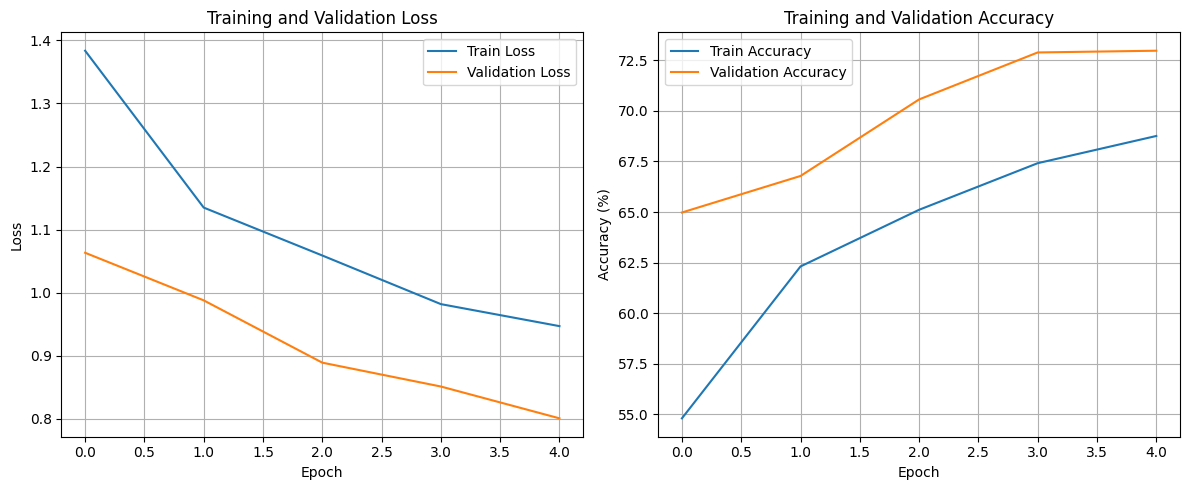

In [ ]:
import matplotlib.pyplot as plt

# 그래프 크기
plt.figure(figsize=(12, 5))

# Loss 그래프
plt.subplot(1, 2, 1)

plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

# Accuracy 그래프
plt.subplot(1, 2, 2)

plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
# 가장 좋은 검증 성능을 기록한 모델 불러오기
model.load_state_dict(
    torch.load(
        "/content/best_garbage_model.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = correct / total * 100

print("최종 테스트 정확도:", round(test_accuracy, 2), "%")

최종 테스트 정확도: 72.72 %


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# 1. 데이터 증강 설정
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor()
])

# 2. 검증 및 테스트용 전처리
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# 3. 증강이 적용된 학습 데이터
aug_dataset = datasets.ImageFolder(
    root=data_dir,
    transform=train_transform
)

# 4. 증강하지 않은 평가 데이터
eval_dataset = datasets.ImageFolder(
    root=data_dir,
    transform=eval_transform
)

# 기존에 사용한 데이터 분리 인덱스 재사용
train_aug_data = Subset(aug_dataset, train_idx)
val_aug_data = Subset(eval_dataset, val_idx)
test_aug_data = Subset(eval_dataset, test_idx)

# 5. DataLoader 생성
train_aug_loader = DataLoader(
    train_aug_data,
    batch_size=32,
    shuffle=True
)

val_aug_loader = DataLoader(
    val_aug_data,
    batch_size=32,
    shuffle=False
)

test_aug_loader = DataLoader(
    test_aug_data,
    batch_size=32,
    shuffle=False
)

print("데이터 증강 설정 완료!")
print("학습 데이터:", len(train_aug_data))
print("검증 데이터:", len(val_aug_data))
print("테스트 데이터:", len(test_aug_data))

데이터 증강 설정 완료!
학습 데이터: 10860
검증 데이터: 2327
테스트 데이터: 2328


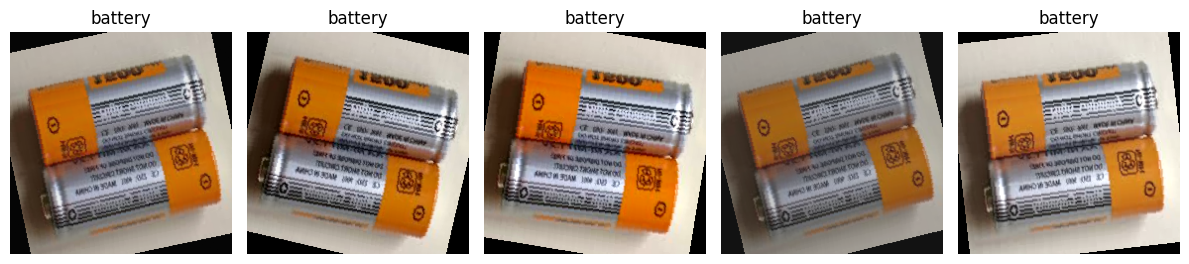

In [ ]:
import matplotlib.pyplot as plt

# 같은 사진을 여러 번 변형해서 확인
sample_image, sample_label = aug_dataset[0]

plt.figure(figsize=(12, 4))

for i in range(5):
    image, label = aug_dataset[0]

    plt.subplot(1, 5, i + 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.title(dataset.classes[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 데이터 증강 모델 새로 만들기
aug_model = GarbageCNN(num_classes=len(dataset.classes)).to(device)

# 손실 함수와 최적화 함수 설정
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(aug_model.parameters(), lr=0.001)

# 학습 횟수
epochs = 5

# 학습 결과 저장
aug_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0

for epoch in range(epochs):

    # 학습 단계
    aug_model.train()
    train_loss = 0.0
    train_correct = 0

    for images, labels in train_aug_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = aug_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()

    train_loss /= len(train_aug_loader.dataset)
    train_acc = train_correct / len(train_aug_loader.dataset)

    # 검증 단계
    aug_model.eval()
    val_loss = 0.0
    val_correct = 0

    with torch.no_grad():
        for images, labels in val_aug_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = aug_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    val_loss /= len(val_aug_loader.dataset)
    val_acc = val_correct / len(val_aug_loader.dataset)

    # 결과 기록
    aug_history["train_loss"].append(train_loss)
    aug_history["train_acc"].append(train_acc)
    aug_history["val_loss"].append(val_loss)
    aug_history["val_acc"].append(val_acc)

    print(f"Epoch [{epoch+1}/{epochs}]")
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    print("-" * 40)

    # 가장 좋은 모델 저장
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(aug_model.state_dict(), "/content/best_aug_garbage_model.pth")

print("데이터 증강 모델 학습 완료!")
print("최고 검증 정확도:", best_val_acc)

Epoch [1/5]
Train Loss: 1.4937, Train Acc: 0.5113
Val Loss: 1.2364, Val Acc: 0.5793
----------------------------------------
Epoch [2/5]
Train Loss: 1.2858, Train Acc: 0.5690
Val Loss: 1.1380, Val Acc: 0.6034
----------------------------------------
Epoch [3/5]
Train Loss: 1.1967, Train Acc: 0.6005
Val Loss: 1.0543, Val Acc: 0.6515
----------------------------------------
Epoch [4/5]
Train Loss: 1.1409, Train Acc: 0.6206
Val Loss: 1.2746, Val Acc: 0.5995
----------------------------------------
Epoch [5/5]
Train Loss: 1.1123, Train Acc: 0.6318
Val Loss: 0.9689, Val Acc: 0.6764
----------------------------------------
데이터 증강 모델 학습 완료!
최고 검증 정확도: 0.6764073914911903


In [27]:
print("기존 모델 최고 검증 정확도:",
      max(history["val_acc"]), "%")

print("데이터 증강 모델 최고 검증 정확도:",
      max(aug_history["val_acc"]) * 100, "%")

기존 모델 최고 검증 정확도: 72.96948861194672 %
데이터 증강 모델 최고 검증 정확도: 67.64073914911903 %


In [23]:
# 실험 C: 학습률 0.0005로 변경

tuned_model = GarbageCNN(num_classes=len(dataset.classes)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(tuned_model.parameters(), lr=0.0005)

tuned_val_acc = []

for epoch in range(3):
    tuned_model.train()

    for images, labels in train_aug_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = tuned_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    tuned_model.eval()
    correct = 0

    with torch.no_grad():
        for images, labels in val_aug_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = tuned_model(images)
            correct += (outputs.argmax(1) == labels).sum().item()

    acc = correct / len(val_aug_loader.dataset)
    tuned_val_acc.append(acc)

    print(f"Epoch [{epoch+1}/3] 검증 정확도: {acc*100:.2f}%")

print("최고 검증 정확도:", max(tuned_val_acc)*100, "%")

torch.save(tuned_model.state_dict(), "/content/tuned_garbage_model.pth")

Epoch [1/3] 검증 정확도: 61.93%
Epoch [2/3] 검증 정확도: 63.99%
Epoch [3/3] 검증 정확도: 60.94%
최고 검증 정확도: 63.98796733992265 %


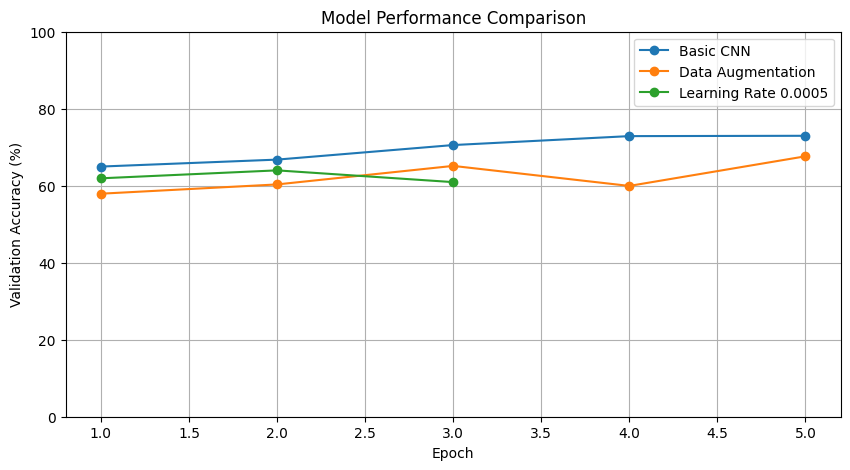

In [25]:
import matplotlib.pyplot as plt

# 정확도 단위 통일
def convert_accuracy(values):
    return [x / 100 if x > 1 else x for x in values]

basic_acc = convert_accuracy(history["val_acc"])
aug_acc = convert_accuracy(aug_history["val_acc"])
tuned_acc = convert_accuracy(tuned_val_acc)

plt.figure(figsize=(10, 5))

plt.plot(range(1, len(basic_acc)+1),
         [x*100 for x in basic_acc],
         marker="o", label="Basic CNN")

plt.plot(range(1, len(aug_acc)+1),
         [x*100 for x in aug_acc],
         marker="o", label="Data Augmentation")

plt.plot(range(1, len(tuned_acc)+1),
         [x*100 for x in tuned_acc],
         marker="o", label="Learning Rate 0.0005")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Model Performance Comparison")
plt.ylim(0, 100)
plt.legend()
plt.grid()
plt.show()